In [1]:
from datasets import load_dataset
import pandas as pd
import numpy as np

RANDOM_STATE = 42

# Load Linguistic Bias dataset
ds = load_dataset("mediabiasgroup/mbib-base")
df = ds["linguistic_bias"].to_pandas()

# Create a copy for cleaning
clean_df = df.copy()

# Normalize text for duplicate detection
clean_df["normalized_text"] = (
    clean_df["text"]
    .fillna("")
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Identify conflicting labels
label_counts = (
    clean_df.groupby("normalized_text")["label"]
    .nunique()
)

conflicting_keys = label_counts[
    label_counts > 1
].index

# Remove conflicting text groups
clean_df = clean_df[
    ~clean_df["normalized_text"].isin(conflicting_keys)
].copy()

# Remove consistent normalized duplicates
clean_df = clean_df.drop_duplicates(
    subset=["normalized_text"],
    keep="first"
).copy()

# Validate dataset
assert clean_df["label"].isin([0, 1]).all()
assert clean_df["normalized_text"].is_unique
assert clean_df["text"].notna().all()

print("Original dataset:", df.shape)
print("Cleaned dataset:", clean_df.shape)

display(clean_df["label"].value_counts())

Original dataset: (401862, 4)
Cleaned dataset: (400657, 5)


label
0    200426
1    200231
Name: count, dtype: int64

In [3]:
from sklearn.model_selection import StratifiedGroupKFold

# Group samples sharing the same ID in Source 75.
# Other sources use a unique group per row.
groups = pd.Series(
    np.where(
        clean_df["dataset_id"] == 75,
        clean_df["dataset_id"].astype(str) + "_" + clean_df["id"].astype(str),
        "row_" + clean_df.index.astype(str)
    ),
    index=clean_df.index
)

# First split: approximately 80% train / 20% temporary
cv_outer = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, temp_idx = next(
    cv_outer.split(
        clean_df["text"],
        clean_df["label"],
        groups
    )
)

train_df = clean_df.iloc[train_idx].copy()
temp_df = clean_df.iloc[temp_idx].copy()

# Second split: temporary data into validation and test
temp_groups = groups.iloc[temp_idx]

cv_inner = StratifiedGroupKFold(
    n_splits=2,
    shuffle=True,
    random_state=42
)

val_idx, test_idx = next(
    cv_inner.split(
        temp_df["text"],
        temp_df["label"],
        temp_groups
    )
)

val_df = temp_df.iloc[val_idx].copy()
test_df = temp_df.iloc[test_idx].copy()

# Check results
for name, subset in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(
        name,
        len(subset),
        f"({len(subset)/len(clean_df)*100:.2f}%)",
        subset["label"].value_counts(normalize=True).round(3).to_dict())

Train 320422 (79.97%) {0: 0.5, 1: 0.5}
Validation 40144 (10.02%) {1: 0.5, 0: 0.5}
Test 40091 (10.01%) {0: 0.501, 1: 0.499}


In [4]:
# Data Leakage Check
# Check text overlap across splits

def check_overlap(col):
    train = set(train_df[col])
    val = set(val_df[col])
    test = set(test_df[col])

    print(f"\n{col} overlap:")
    print("Train / Validation:", len(train & val))
    print("Train / Test:", len(train & test))
    print("Validation / Test:", len(val & test))


check_overlap("normalized_text")

# Check related IDs in Source 75
train_ids = set(train_df.loc[train_df["dataset_id"] == 75, "id"])
val_ids = set(val_df.loc[val_df["dataset_id"] == 75, "id"])
test_ids = set(test_df.loc[test_df["dataset_id"] == 75, "id"])

print("\nSource 75 ID overlap:")
print("Train / Validation:", len(train_ids & val_ids))
print("Train / Test:", len(train_ids & test_ids))
print("Validation / Test:", len(val_ids & test_ids))

# Verify all records are accounted for
assert len(train_df) + len(val_df) + len(test_df) == len(clean_df)


normalized_text overlap:
Train / Validation: 0
Train / Test: 0
Validation / Test: 0

Source 75 ID overlap:
Train / Validation: 0
Train / Test: 0
Validation / Test: 0


In [5]:
print("Train shape:", train_df.shape)
print("Validation shape:", val_df.shape)

print("\nTrain labels:")
print(train_df["label"].value_counts())

print("\nValidation labels:")
print(val_df["label"].value_counts())

print("\nMissing text values:")
print("Train:", train_df["text"].isna().sum())
print("Validation:", val_df["text"].isna().sum())

Train shape: (320422, 5)
Validation shape: (40144, 5)

Train labels:
label
0    160286
1    160136
Name: count, dtype: int64

Validation labels:
label
1    20080
0    20064
Name: count, dtype: int64

Missing text values:
Train: 0
Validation: 0


In [6]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import FeatureUnion

# Small, balanced training sample
experiment_df, _ = train_test_split(
    train_df,
    train_size=20000,
    stratify=train_df["label"],
    random_state=42
)

word_vectorizer = TfidfVectorizer(
    analyzer="word",
    ngram_range=(1, 2),
    max_features=20000,
    min_df=2,
    sublinear_tf=True
)

char_vectorizer = TfidfVectorizer(
    analyzer="char",
    ngram_range=(3, 5),
    max_features=20000,
    min_df=2,
    sublinear_tf=True
)

combined_vectorizer = FeatureUnion([
    ("word", word_vectorizer),
    ("char", char_vectorizer)
])

print("Experiment samples:", len(experiment_df))
print("Labels:")
print(experiment_df["label"].value_counts())
print("Vectorizer ready!")

Experiment samples: 20000
Labels:
label
0    10005
1     9995
Name: count, dtype: int64
Vectorizer ready!


In [7]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
import time

combined_pipeline = Pipeline([
    ("vectorizer", combined_vectorizer),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

start = time.perf_counter()

combined_pipeline.fit(
    experiment_df["text"],
    experiment_df["label"]
)

training_time = time.perf_counter() - start

val_probs = combined_pipeline.predict_proba(
    val_df["text"]
)[:, 1]

combined_auc = roc_auc_score(
    val_df["label"],
    val_probs
)

print(f"Training time: {training_time:.2f} seconds")
print(f"Validation ROC-AUC: {combined_auc:.4f}")

Training time: 5.46 seconds
Validation ROC-AUC: 0.6479


In [8]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
import time

combined_pipeline = Pipeline([
    ("vectorizer", combined_vectorizer),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

start = time.perf_counter()

combined_pipeline.fit(
    experiment_df["text"],
    experiment_df["label"]
)

training_time = time.perf_counter() - start

val_probs = combined_pipeline.predict_proba(
    val_df["text"]
)[:, 1]

combined_auc = roc_auc_score(
    val_df["label"],
    val_probs
)

print(f"Training time: {training_time:.2f} seconds")
print(f"Validation ROC-AUC: {combined_auc:.4f}")

Training time: 5.54 seconds
Validation ROC-AUC: 0.6479


In [9]:
from sklearn.base import clone

word_pipeline = Pipeline([
    ("vectorizer", clone(word_vectorizer)),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

start = time.perf_counter()

word_pipeline.fit(
    experiment_df["text"],
    experiment_df["label"]
)

word_probs = word_pipeline.predict_proba(
    val_df["text"]
)[:, 1]

word_auc = roc_auc_score(
    val_df["label"],
    word_probs
)

print(f"Word-only ROC-AUC: {word_auc:.4f}")
print(f"Word + Character ROC-AUC: {combined_auc:.4f}")
print(f"Difference: {combined_auc - word_auc:+.4f}")
print(f"Time: {time.perf_counter() - start:.2f} seconds")

Word-only ROC-AUC: 0.6343
Word + Character ROC-AUC: 0.6479
Difference: +0.0136
Time: 2.34 seconds


In [10]:
experiment_40k_df, _ = train_test_split(
    train_df,
    train_size=40000,
    stratify=train_df["label"],
    random_state=42
)

combined_40k_pipeline = clone(combined_pipeline)

start = time.perf_counter()

combined_40k_pipeline.fit(
    experiment_40k_df["text"],
    experiment_40k_df["label"]
)

probs_40k = combined_40k_pipeline.predict_proba(
    val_df["text"]
)[:, 1]

auc_40k = roc_auc_score(
    val_df["label"],
    probs_40k
)

print(f"Training samples: {len(experiment_40k_df):,}")
print(f"Training time: {time.perf_counter() - start:.2f} seconds")
print(f"Validation ROC-AUC: {auc_40k:.4f}")

Training samples: 40,000
Training time: 21.20 seconds
Validation ROC-AUC: 0.6622


In [11]:
experiment_100k_df, _ = train_test_split(
    train_df,
    train_size=100000,
    stratify=train_df["label"],
    random_state=42
)

combined_100k_pipeline = clone(combined_pipeline)

start = time.perf_counter()

combined_100k_pipeline.fit(
    experiment_100k_df["text"],
    experiment_100k_df["label"]
)

probs_100k = combined_100k_pipeline.predict_proba(
    val_df["text"]
)[:, 1]

auc_100k = roc_auc_score(
    val_df["label"],
    probs_100k
)

print(f"Training samples: {len(experiment_100k_df):,}")
print(f"Training time: {time.perf_counter() - start:.2f} seconds")
print(f"Validation ROC-AUC: {auc_100k:.4f}")

Training samples: 100,000
Training time: 40.87 seconds
Validation ROC-AUC: 0.6765


In [12]:
experiment_200k_df, _ = train_test_split(
    train_df,
    train_size=200000,
    stratify=train_df["label"],
    random_state=42
)

combined_200k_pipeline = clone(combined_pipeline)

start = time.perf_counter()

combined_200k_pipeline.fit(
    experiment_200k_df["text"],
    experiment_200k_df["label"]
)

probs_200k = combined_200k_pipeline.predict_proba(
    val_df["text"]
)[:, 1]

auc_200k = roc_auc_score(
    val_df["label"],
    probs_200k
)

print(f"Training samples: {len(experiment_200k_df):,}")
print(f"Training time: {time.perf_counter() - start:.2f} seconds")
print(f"Validation ROC-AUC: {auc_200k:.4f}")

Training samples: 200,000
Training time: 74.16 seconds
Validation ROC-AUC: 0.6867


In [13]:
combined_full_pipeline = clone(combined_pipeline)

start = time.perf_counter()

combined_full_pipeline.fit(
    train_df["text"],
    train_df["label"]
)

probs_full = combined_full_pipeline.predict_proba(
    val_df["text"]
)[:, 1]

auc_full = roc_auc_score(
    val_df["label"],
    probs_full
)

print(f"Training samples: {len(train_df):,}")
print(f"Training time: {time.perf_counter() - start:.2f} seconds")
print(f"Validation ROC-AUC: {auc_full:.4f}")
print(f"Improvement over original LR: {auc_full - 0.6838:+.4f}")

Training samples: 320,422
Training time: 106.80 seconds
Validation ROC-AUC: 0.6950
Improvement over original LR: +0.0112


## Model Comparison & Cross-Validation

In [15]:
import time
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedGroupKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

SEED = 42
BASELINE_AUC = 0.6838

assert train_df["label"].nunique() == 2
assert val_df["label"].nunique() == 2
assert train_df["text"].notna().all()
assert val_df["text"].notna().all()

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Columns:", train_df.columns.tolist())

Training: 320422
Validation: 40144
Columns: ['id', 'text', 'label', 'dataset_id', 'normalized_text']


In [16]:
def make_word_vectorizer():
    return TfidfVectorizer(
        analyzer="word",
        ngram_range=(1, 2),
        max_features=20000,
        min_df=2,
        sublinear_tf=True
    )

def make_combined_vectorizer():
    return FeatureUnion([
        ("word", make_word_vectorizer()),
        ("char", TfidfVectorizer(
            analyzer="char",
            ngram_range=(3, 5),
            max_features=20000,
            min_df=2,
            sublinear_tf=True
        ))
    ])

models = {
    "Logistic Regression": Pipeline([
        ("vectorizer", make_word_vectorizer()),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=SEED
        ))
    ]),
    "LinearSVC": Pipeline([
        ("vectorizer", make_word_vectorizer()),
        ("classifier", LinearSVC(
            C=0.02,
            random_state=SEED,
            max_iter=5000
        ))
    ]),
    "Word + Character LR": Pipeline([
        ("vectorizer", make_combined_vectorizer()),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=SEED
        ))
    ])
}

print("Models ready:", list(models))

Models ready: ['Logistic Regression', 'LinearSVC', 'Word + Character LR']


In [17]:
size_results = []

for size in [5000, 10000]:

    sample_df, _ = train_test_split(
        train_df,
        train_size=size,
        stratify=train_df["label"],
        random_state=SEED
    )

    X_train_exp = sample_df["text"]
    y_train_exp = sample_df["label"]
    X_val_exp = val_df["text"]
    y_val_exp = val_df["label"]

    for name in ["Logistic Regression", "LinearSVC"]:

        model = clone(models[name])

        start = time.perf_counter()
        model.fit(X_train_exp, y_train_exp)

        if hasattr(model, "predict_proba"):
            scores = model.predict_proba(X_val_exp)[:, 1]
        else:
            scores = model.decision_function(X_val_exp)

        auc = roc_auc_score(y_val_exp, scores)

        size_results.append({
            "Model": name,
            "Train Size": size,
            "ROC-AUC": auc,
            "Time (s)": time.perf_counter() - start
        })

        print(f"{name} | {size:,} samples | ROC-AUC: {auc:.4f}")

size_results_df = pd.DataFrame(size_results)
display(size_results_df.round(4))

Logistic Regression | 5,000 samples | ROC-AUC: 0.6055
LinearSVC | 5,000 samples | ROC-AUC: 0.6002
Logistic Regression | 10,000 samples | ROC-AUC: 0.6221
LinearSVC | 10,000 samples | ROC-AUC: 0.6122


,Model,Train Size,ROC-AUC,Time (s)
0,Logistic Regression,5000,0.6055,1.4342
1,LinearSVC,5000,0.6002,1.2836
2,Logistic Regression,10000,0.6221,1.8555
3,LinearSVC,10000,0.6122,1.6185


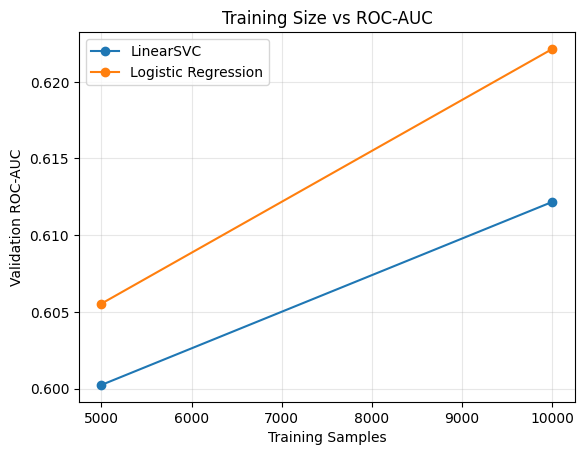

In [18]:
for model_name, group in size_results_df.groupby("Model"):
    plt.plot(
        group["Train Size"],
        group["ROC-AUC"],
        marker="o",
        label=model_name
    )

plt.xlabel("Training Samples")
plt.ylabel("Validation ROC-AUC")
plt.title("Training Size vs ROC-AUC")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [19]:
# Adjust these only if your column names are different
SOURCE_COLUMN = "dataset_id"
ID_COLUMN = "id"

cv_df, _ = train_test_split(
    train_df,
    train_size=40000,
    stratify=train_df["label"],
    random_state=SEED
)

# Required for the previously identified shared-ID issue
if SOURCE_COLUMN not in cv_df.columns:
    raise ValueError(
        f"Source column not found. Available: {cv_df.columns.tolist()}"
    )

if ID_COLUMN not in cv_df.columns:
    raise ValueError(
        f"ID column not found. Available: {cv_df.columns.tolist()}"
    )

# Same normalization used for text-overlap checks:
# lowercase + whitespace normalization
normalized_text = (
    cv_df["text"]
    .astype(str)
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

source_values = cv_df[SOURCE_COLUMN].astype("string").fillna("")
id_values = cv_df[ID_COLUMN].astype("string")

# Union linked rows into the same group
parent = list(range(len(cv_df)))

def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i

def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[rb] = ra

text_owner = {}
id_owner = {}

for i, (text_value, source, record_id) in enumerate(
    zip(normalized_text, source_values, id_values)
):
    if text_value in text_owner:
        union(i, text_owner[text_value])
    else:
        text_owner[text_value] = i

    # Group shared IDs within the same source dataset
    if pd.notna(record_id) and str(record_id).strip():
        key = (str(source), str(record_id))

        if key in id_owner:
            union(i, id_owner[key])
        else:
            id_owner[key] = i

cv_groups = np.array([find(i) for i in range(len(cv_df))])

print("CV samples:", len(cv_df))
print("Unique groups:", len(np.unique(cv_groups)))
print("Labels:")
print(cv_df["label"].value_counts())

CV samples: 40000
Unique groups: 39887
Labels:
label
0    20009
1    19991
Name: count, dtype: int64


In [20]:
#Run 5-Fold Cross-Validation
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

X_cv = cv_df["text"].reset_index(drop=True)
y_cv = cv_df["label"].reset_index(drop=True)

cv_results = []

for model_name, estimator in models.items():

    print(f"\n{'=' * 50}")
    print(f"Model: {model_name}")
    print(f"{'=' * 50}")

    for fold, (train_idx, valid_idx) in enumerate(
        cv.split(X_cv, y_cv, groups=cv_groups),
        start=1
    ):

        model = clone(estimator)

        X_train_fold = X_cv.iloc[train_idx]
        y_train_fold = y_cv.iloc[train_idx]

        X_valid_fold = X_cv.iloc[valid_idx]
        y_valid_fold = y_cv.iloc[valid_idx]

        start = time.perf_counter()

        model.fit(X_train_fold, y_train_fold)

        predictions = model.predict(X_valid_fold)

        if hasattr(model, "predict_proba"):
            scores = model.predict_proba(X_valid_fold)[:, 1]
        else:
            scores = model.decision_function(X_valid_fold)

        fold_result = {
            "Model": model_name,
            "Fold": fold,
            "ROC-AUC": roc_auc_score(y_valid_fold, scores),
            "Precision": precision_score(
                y_valid_fold, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_valid_fold, predictions, zero_division=0
            ),
            "F1": f1_score(
                y_valid_fold, predictions, zero_division=0
            ),
            "Time (s)": time.perf_counter() - start
        }

        cv_results.append(fold_result)

        print(
            f"Fold {fold} | "
            f"AUC: {fold_result['ROC-AUC']:.4f} | "
            f"F1: {fold_result['F1']:.4f}"
        )

cv_results_df = pd.DataFrame(cv_results)

display(cv_results_df.round(4))


Model: Logistic Regression
Fold 1 | AUC: 0.6396 | F1: 0.5704
Fold 2 | AUC: 0.6377 | F1: 0.5693
Fold 3 | AUC: 0.6436 | F1: 0.5767
Fold 4 | AUC: 0.6558 | F1: 0.5857
Fold 5 | AUC: 0.6542 | F1: 0.5882

Model: LinearSVC
Fold 1 | AUC: 0.6363 | F1: 0.5385
Fold 2 | AUC: 0.6334 | F1: 0.5392
Fold 3 | AUC: 0.6382 | F1: 0.5405
Fold 4 | AUC: 0.6470 | F1: 0.5554
Fold 5 | AUC: 0.6404 | F1: 0.5480

Model: Word + Character LR
Fold 1 | AUC: 0.6584 | F1: 0.5924
Fold 2 | AUC: 0.6532 | F1: 0.5900
Fold 3 | AUC: 0.6591 | F1: 0.5955
Fold 4 | AUC: 0.6715 | F1: 0.6036
Fold 5 | AUC: 0.6686 | F1: 0.6014


,Model,Fold,ROC-AUC,Precision,Recall,F1,Time (s)
0,Logistic Regression,1,0.6396,0.6093,0.5361,0.5704,2.6546
1,Logistic Regression,2,0.6377,0.6008,0.5409,0.5693,2.4944
2,Logistic Regression,3,0.6436,0.6223,0.5373,0.5767,2.5023
3,Logistic Regression,4,0.6558,0.6177,0.5568,0.5857,2.5272
4,Logistic Regression,5,0.6542,0.6132,0.5651,0.5882,2.5573
5,LinearSVC,1,0.6363,0.6205,0.4756,0.5385,2.4656
6,LinearSVC,2,0.6334,0.6169,0.4789,0.5392,2.5683
7,LinearSVC,3,0.6382,0.6340,0.4711,0.5405,2.4644
8,LinearSVC,4,0.6470,0.6277,0.4980,0.5554,2.4329
9,LinearSVC,5,0.6404,0.6188,0.4917,0.5480,2.4472


In [21]:
# Compare Cross-Validation Results
metrics = ["ROC-AUC", "Precision", "Recall", "F1"]

cv_summary = (
    cv_results_df
    .groupby("Model")[metrics]
    .agg(["mean", "std"])
)

display(cv_summary.round(4))

best_model_name = (
    cv_results_df
    .groupby("Model")["ROC-AUC"]
    .mean()
    .idxmax()
)

print("\nBest Model by mean CV ROC-AUC:", best_model_name)
print(
    "Mean ROC-AUC:",
    round(
        cv_results_df
        .query("Model == @best_model_name")["ROC-AUC"]
        .mean(),
        4
    )
)

ROC-AUC         Precision          Recall              F1  \
                       mean     std      mean     std    mean     std    mean   
Model                                                                           
LinearSVC            0.6391  0.0051    0.6236  0.0071  0.4830  0.0113  0.5443   
Logistic Regression  0.6462  0.0083    0.6127  0.0082  0.5473  0.0130  0.5780   
Word + Character LR  0.6622  0.0076    0.6227  0.0071  0.5726  0.0091  0.5966   

                             
                        std  
Model                        
LinearSVC            0.0073  
Logistic Regression  0.0086  
Word + Character LR  0.0058


Best Model by mean CV ROC-AUC: Word + Character LR
Mean ROC-AUC: 0.6622


In [22]:
dev_df = pd.concat(
    [train_df, val_df],
    ignore_index=True
)

final_model = clone(models["Word + Character LR"])

final_model.fit(
    dev_df["text"],
    dev_df["label"]
)

print("Training samples:", len(dev_df))

Training samples: 360566


FINAL TEST RESULTS
------------------
ROC-AUC: 0.6959
Precision: 0.6647
Recall: 0.5699
F1: 0.6137

Classification Report:
              precision    recall  f1-score   support

    Unbiased       0.62      0.71      0.67     20076
      Biased       0.66      0.57      0.61     20015

    accuracy                           0.64     40091
   macro avg       0.64      0.64      0.64     40091
weighted avg       0.64      0.64      0.64     40091



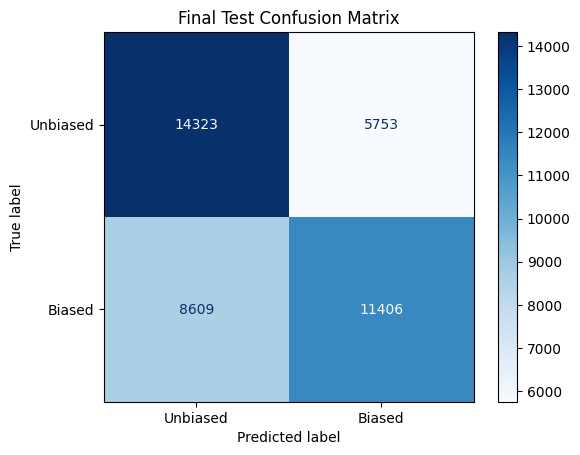

In [23]:

RUN_FINAL_TEST = True

if RUN_FINAL_TEST:

    if "final_model" not in globals():
        raise RuntimeError("Train the final model first.")

    X_test = test_df["text"]
    y_test = test_df["label"]

    test_predictions = final_model.predict(X_test)

    if hasattr(final_model, "predict_proba"):
        test_scores = final_model.predict_proba(X_test)[:, 1]
    else:
        test_scores = final_model.decision_function(X_test)

    print("FINAL TEST RESULTS")
    print("------------------")
    print(f"ROC-AUC: {roc_auc_score(y_test, test_scores):.4f}")
    print(f"Precision: {precision_score(y_test, test_predictions):.4f}")
    print(f"Recall: {recall_score(y_test, test_predictions):.4f}")
    print(f"F1: {f1_score(y_test, test_predictions):.4f}")

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        test_predictions,
        target_names=["Unbiased", "Biased"]
    ))

    cm = confusion_matrix(y_test, test_predictions)

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Unbiased", "Biased"]
    ).plot(cmap="Blues")

    plt.title("Final Test Confusion Matrix")
    plt.show()

In [24]:
demo_texts = [
    "The committee announced its decision yesterday.",
    "Women are naturally less capable of leading technical teams.",
    "The new policy will affect several departments.",
    "People from that community cannot be trusted."
]

# Run only after final training
if "final_model" in globals():

    demo_predictions = final_model.predict(demo_texts)

    if hasattr(final_model, "predict_proba"):
        demo_scores = final_model.predict_proba(demo_texts)[:, 1]
    else:
        demo_scores = final_model.decision_function(demo_texts)

    demo_df = pd.DataFrame({
        "Text": demo_texts,
        "Prediction": [
            "Biased" if p == 1 else "Unbiased"
            for p in demo_predictions
        ],
        "Model Score": demo_scores
    })

    display(demo_df)

,Text,Prediction,Model Score
0,The committee announced its decision yesterday.,Unbiased,0.429840
1,Women are naturally less capable of leading te...,Biased,0.707270
2,The new policy will affect several departments.,Unbiased,0.343158
3,People from that community cannot be trusted.,Unbiased,0.319342


In [25]:
from pathlib import Path
import joblib
import numpy as np

# Find the project root
repo_root = next(
    (
        p for p in [Path.cwd(), *Path.cwd().parents]
        if (p / "models").is_dir()
        and (p / "notebooks").is_dir()
    ),
    None
)

if repo_root is None:
    raise FileNotFoundError("BiasLens project root not found.")

model_path = repo_root / "models" / "linguistic_bias_lr_word_char.joblib"

# Save final trained pipeline
joblib.dump(final_model, model_path)

# Verify the saved model
loaded_model = joblib.load(model_path)

original_probs = final_model.predict_proba(demo_texts)[:, 1]
loaded_probs = loaded_model.predict_proba(demo_texts)[:, 1]

print("Model saved:", model_path)
print("Reload verification:", np.allclose(original_probs, loaded_probs))
print("Model size (MB):", round(model_path.stat().st_size / 1024**2, 2))

Model saved: /Users/sarahaltaleb/Documents/GitHub/BiasLens/models/linguistic_bias_lr_word_char.joblib
Reload verification: True
Model size (MB): 1.7
